# 01 — Exploratory Data Analysis

**Kaggle Titanic** — understand the data before touching any model.

Sections:
0. Findings summary *(filled in after the analysis)*
1. First look — shapes, dtypes, preview
2. Missing-value audit
3. Distributions
4. Survival analysis — conditional probability in action
5. Leakage screen


## 0. Findings summary

1. **Base rate:** 38.4% of train passengers survived — the number any model must beat.
2. **The dumb rule is strong:** "all women survive" scores **78.7%** accuracy on train — and `gender_submission.csv` (Kaggle's example file) is exactly that rule. A model only adds value if it beats this.
3. **Sex dominates, but class modulates it:** women 74.2% vs men 18.9% overall — yet 1st-class women 96.8% vs 3rd-class women 50.0%, and 1st-class men 36.9% vs 3rd-class men 13.5%. **Interactions matter** → tree models (and engineered features) should beat a purely linear one.
4. **Fare is monotone with survival** (19.7% in the cheapest quartile → 58.1% in the dearest) but heavily skewed (4.79; median 14.45 vs mean 32.2) → prefer median-based handling, consider log/binning.
5. **Age is non-linear:** children 0–12 survive most (57.4%), elderly 60+ least (24.0%) → keep as a numeric feature and let trees find the split; 19.9% missing → median imputation required.
6. **FamilySize is non-monotonic:** traveling alone 30.4%, families of 2–4 ~55–72%, large families (5+) collapse (<21%) → engineer `IsAlone` + `FamilySize`.
7. **Cabin is 77% missing** → a `has_cabin` flag likely carries more signal than the cabin code itself.
8. **Leakage screen clean:** no outcome-derived columns; the only train-only column is the target. test.csv has 1 missing Fare and 20.6% missing Age — the pipeline must impute at predict time.


## 1. First look

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="darkgrid")
pd.set_option("display.max_columns", None)

RAW = Path("../data/raw")

In [2]:
train = pd.read_csv(RAW / "train.csv")
test = pd.read_csv(RAW / "test.csv")
gender_submission = pd.read_csv(RAW / "gender_submission.csv")

print("train:", train.shape, "| test:", test.shape)
train.head()

train: (891, 12) | test: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


**Read of the schema:**
- `Survived` is the **target** (1 = survived, 0 = died) — train only.
- `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked` are plausible **features**.
- `Name`, `Ticket`, `Cabin` are text/high-cardinality — need transformation or dropping.
- `PassengerId` is an identifier, not a feature.

## 2. Missing-value audit

In [4]:
def missing_table(df: pd.DataFrame) -> pd.DataFrame:
    table = pd.DataFrame({
        "count": df.isna().sum(),
        "pct": (df.isna().mean() * 100).round(1),
    })
    return table[table["count"] > 0].sort_values("pct", ascending=False)

print("--- train ---")
missing_table(train)

--- train ---


,count,pct
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


In [5]:
print("--- test ---")
missing_table(test)

--- test ---


,count,pct
Cabin,327,78.2
Age,86,20.6
Fare,1,0.2


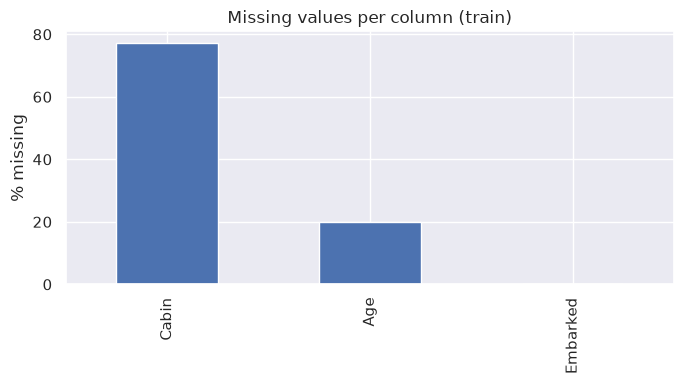

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
missing_table(train)["pct"].plot.bar(ax=ax)
ax.set_ylabel("% missing")
ax.set_title("Missing values per column (train)")
plt.tight_layout()
plt.show()

**Takeaways so far:** Age (~20% missing in both files) needs imputation; Cabin (~77% missing) is mostly absent — a `has_cabin` flag may carry more signal than the cabin code; Embarked has 2 missing rows — trivial to fill.

## 3. Distributions

In [7]:
base_rate = train["Survived"].mean()
print(f"Overall survival rate: {base_rate:.1%}  (this is the number a dumb model must beat)")

Overall survival rate: 38.4%  (this is the number a dumb model must beat)


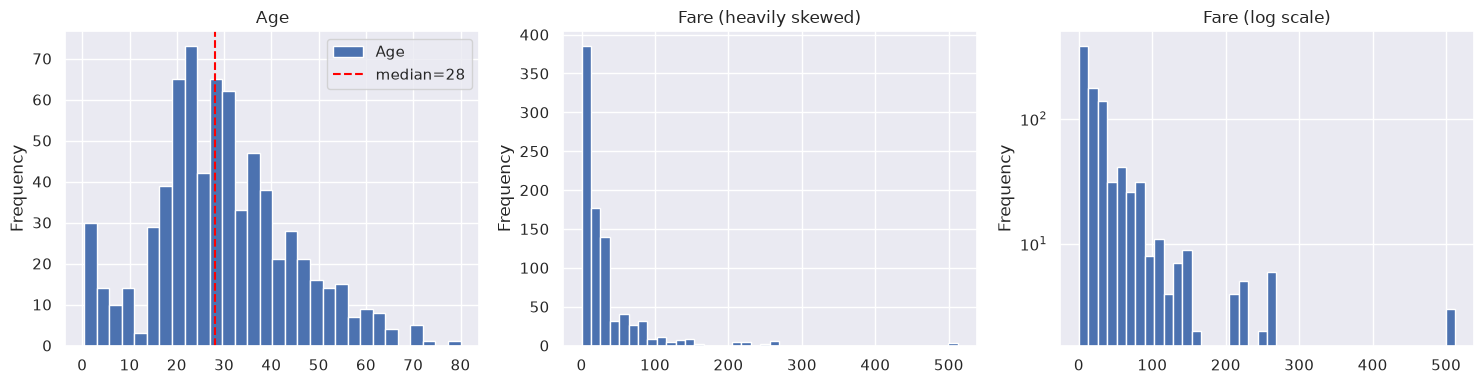

Fare skew: 4.79 -> median 14.4542 vs mean 32.2


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

train["Age"].plot.hist(bins=30, ax=axes[0], title="Age")
axes[0].axvline(train["Age"].median(), color="red", linestyle="--", label=f"median={train['Age'].median():.0f}")
axes[0].legend()

train["Fare"].plot.hist(bins=40, ax=axes[1], title="Fare (heavily skewed)")
train["Fare"].plot.hist(bins=40, ax=axes[2], logy=True, title="Fare (log scale)")

plt.tight_layout()
plt.show()

print("Fare skew:", round(train["Fare"].skew(), 2), "-> median", train["Fare"].median(), "vs mean", round(train["Fare"].mean(), 1))

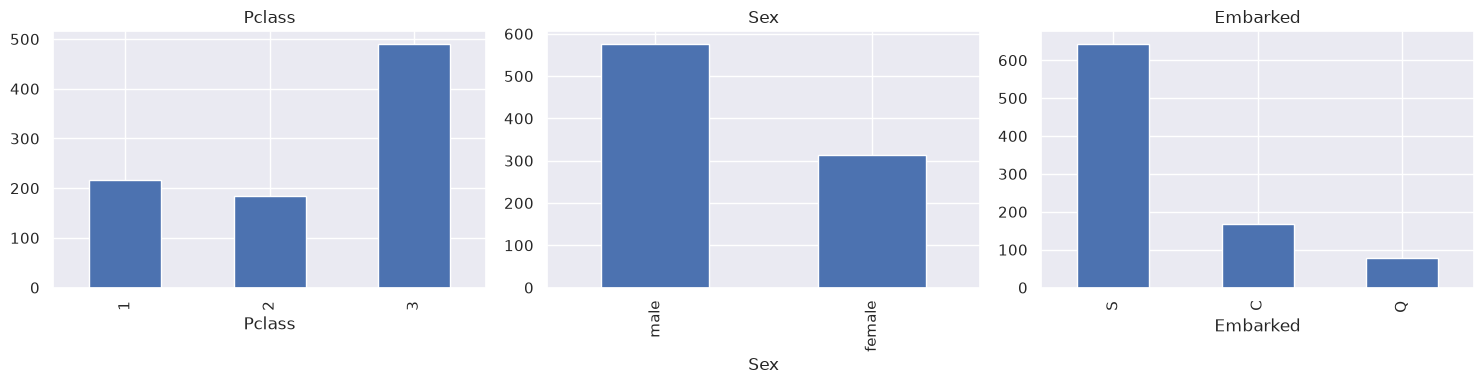

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
train["Pclass"].value_counts().sort_index().plot.bar(ax=axes[0], title="Pclass")
train["Sex"].value_counts().plot.bar(ax=axes[1], title="Sex")
train["Embarked"].value_counts().plot.bar(ax=axes[2], title="Embarked")
plt.tight_layout()
plt.show()

## 4. Survival analysis — conditional probability in action

Every number below is a **conditional probability**: P(survived | group).

In [10]:
for col in ["Sex", "Pclass", "Embarked"]:
    rates = train.groupby(col, observed=True)["Survived"].agg(["mean", "count"])
    rates["mean"] = (rates["mean"] * 100).round(1)
    print(f"--- survival rate by {col} (%) ---")
    print(rates.rename(columns={"mean": "survived_%"}), "\n")

--- survival rate by Sex (%) ---
        survived_%  count
Sex                      
female        74.2    314
male          18.9    577 

--- survival rate by Pclass (%) ---
        survived_%  count
Pclass                   
1             63.0    216
2             47.3    184
3             24.2    491 

--- survival rate by Embarked (%) ---
          survived_%  count
Embarked                   
C               55.4    168
Q               39.0     77
S               33.7    644 



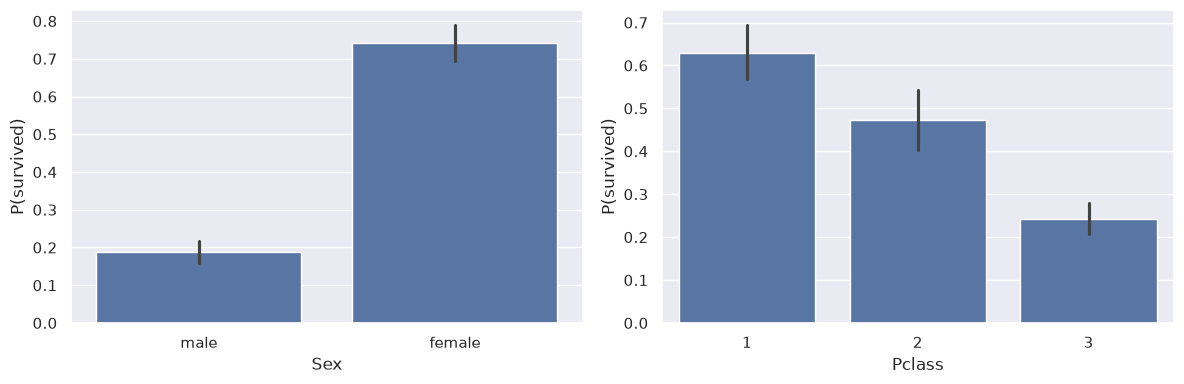

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=train, x="Sex", y="Survived", ax=axes[0])
sns.barplot(data=train, x="Pclass", y="Survived", ax=axes[1])
axes[0].set_ylabel("P(survived)"); axes[1].set_ylabel("P(survived)")
plt.tight_layout()
plt.show()

In [12]:
# The famous rule, quantified: what does "women and children first" score?
sex_rate = train.groupby("Sex")["Survived"].mean()
women = train["Sex"] == "female"
rule_pred = women.astype(int)
rule_accuracy = (rule_pred == train["Survived"]).mean()

print(f"'All women survive' rule accuracy on train: {rule_accuracy:.1%}")
print(f"(gender_submission.csv — Kaggle's example file — IS this rule)")
print(f"All-male survival rate: {sex_rate['male']:.1%} | all-female: {sex_rate['female']:.1%}")

'All women survive' rule accuracy on train: 78.7%
(gender_submission.csv — Kaggle's example file — IS this rule)
All-male survival rate: 18.9% | all-female: 74.2%


In [13]:
# Interaction: class matters inside sex
pd.pivot_table(train, index="Sex", columns="Pclass", values="Survived", aggfunc="mean").round(3)

Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


In [14]:
# Age bands — is "children first" real in the data?
train["AgeBand"] = pd.cut(train["Age"], bins=[0, 12, 18, 35, 60, 80], right=False)
train.groupby("AgeBand", observed=True)["Survived"].agg(["mean", "count"]).round(3)

,mean,count
AgeBand,,
"[0, 12)",0.574,68
"[12, 18)",0.489,45
"[18, 35)",0.369,366
"[35, 60)",0.416,209
"[60, 80)",0.240,25


In [15]:
# Fare quartiles
train["FareBand"] = pd.qcut(train["Fare"], 4)
train.groupby("FareBand", observed=True)["Survived"].agg(["mean", "count"]).round(3)

,mean,count
FareBand,,
"(-0.001, 7.91]",0.197,223
"(7.91, 14.454]",0.304,224
"(14.454, 31.0]",0.455,222
"(31.0, 512.329]",0.581,222


In [16]:
# Family size: traveling alone vs with family
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1
train.groupby("FamilySize")["Survived"].agg(["mean", "count"]).round(3)

,mean,count
FamilySize,,
1,0.304,537
2,0.553,161
3,0.578,102
4,0.724,29
5,0.200,15
6,0.136,22
7,0.333,12
8,0.000,6
11,0.000,7


## 5. Leakage screen

**Leakage** = using information at training time that wouldn't be available when the model actually predicts. On Titanic it's mostly about *which columns are knowable for a new passenger*:

- ✅ Knowable at prediction: Pclass, Sex, Age, SibSp, Parch, Fare, Embarked, Name (title!), Cabin (if recorded), Ticket.
- ⚠️ `Age` is missing for ~20% — a model must handle NaN at predict time (imputation, not dropping rows).
- 🎯 `Survived` exists only in train — that's the target; it must never appear in features.
- 🔎 Nothing here is derived from the outcome, so the classic leakage trap is avoided — but we re-check after feature engineering on Tuesday.

In [17]:
# Sanity: no target column in test
assert "Survived" not in test.columns
print("OK: test.csv has no target column (as expected)")
print("Columns only in train:", set(train.columns) - set(test.columns))

OK: test.csv has no target column (as expected)
Columns only in train: {'Survived', 'FareBand', 'AgeBand', 'FamilySize'}
